### Load Packages

In [1]:
import os
import pathlib
import sys
#arithmetic libraries
import numpy  as np
import pandas as pd
#ploting libraries
import matplotlib.pyplot as plt
#user functions
sys.path.insert(0,'../python_lib/statistics')
sys.path.insert(0,'../python_lib/vel_prof')
sys.path.insert(0,'../python_lib/plotting')
sys.path.insert(0,'../implementation')
sys.path.insert(0,'../miscellaneous')
sys.path.insert(0,'../python_lib/usgs')
#plotting
import pylib_contour_plots as pycplt
import geopandas as gpd
from shapely.geometry import Polygon
#vs30 map
from query_willis15_ca_vs30_map import Willis15Vs30CA as willis15vs30
#usgs vel model
#from query_usgs_v21 import USGSVelModelv21 as velmodel_usgs
#velocity model
#from vel_model import VelModelStationary as velmodel_stat
#from vel_model import VelModelSpatialVarying as velmodel_svar

#%% Define Variables
### ======================================
#velocity model exents
# vel_model_ext = np.array( [[-120.644051, -121.922036, -123.858493, -122.562365, -120.644051],
#                            [37.050062,    36.320331,   38.424179,   39.174505,   37.050062]])
#velocity model exents (~1% shrinked)
vel_model_ext = np.array([[-119.525 , -116.91 , -119.525, -116.91, -119.525 ],
                          [  34.744 ,  34.744 ,   33.49,   33.49,   34.744 ]])

#number points
# n_discrt = 1000
n_discrt = 500
# n_discrt = 100


In [2]:

#depth
# z = np.array([0.,])
# z = np.array([10.,])
# z = np.array([30.,])
z = np.array([0.,30.,])
# z = np.array([100.,])

#color bar limits
if z[0] == 0:
    lims_vs  = [50, 1000]
    lims_unc = [0., .10]
elif z[0] == 10:
    lims_vs  = [50, 1200]
    lims_unc = [0., .10]    
elif z[0] == 30:
    lims_vs  = [200, 1300]
    lims_unc = [0., .10]
elif z[0] == 50:
    lims_vs  = [250, 1500]
    lims_unc = [0., .13]
elif z[0] == 100:
    lims_vs  = [400, 1600]
    lims_unc = [0., .15]

#filename spatially varying parametes
#fname_model_svar_dBr = '../../Data/regression/model_spatially_varying_old/all_trunc_stan_parameters2.csv'

#usgs vel model
#dir_usgs   = '/mnt/halcloud_nfs/glavrent/Research/GP_Vel_profiles/Raw_files/vel_model/USGS_SFB_vel_model/'
#dir_usgs   = '/home/glavrent/Downloads/'
#fname_usgs = 'USGS_SFCVM_v21-1_detailed.h5'

#figure directory
#dir_fig = '../../Data/misc/comparison_maps/'

#main figure title
#fname_fig_main = 'map_original_'


In [3]:
df_ucvm = pd.read_csv('vs30_df.txt', encoding='utf-8')
df_ucvm

,cell_id,vs30_pred,easting,northing,long,lat
0,1,2715.387792,264942.878321,3.705615e+06,-119.5293,33.4642
1,2,2717.219625,265442.878321,3.705615e+06,-119.5239,33.4643
2,3,2718.503958,265942.878321,3.705615e+06,-119.5185,33.4644
3,4,2719.836542,266442.878321,3.705615e+06,-119.5131,33.4646
4,5,2722.482083,266942.878321,3.705615e+06,-119.5077,33.4647
...,...,...,...,...,...,...
138871,138872,2436.486375,506942.878321,3.847115e+06,-116.9241,34.7662
138872,138873,2441.125625,507442.878321,3.847115e+06,-116.9187,34.7662
138873,138874,2446.035250,507942.878321,3.847115e+06,-116.9132,34.7662
138874,138875,2453.740292,508442.878321,3.847115e+06,-116.9077,34.7662


In [4]:
mesh_array = df_ucvm[["long", "lat"]].to_numpy()  
model_w15ca_vs30 = willis15vs30()
vs30_mu_array, vs30_sd_array = model_w15ca_vs30.lookup(mesh_array)

In [5]:
df_ucvm['wills'] = vs30_mu_array
df_ucvm

,cell_id,vs30_pred,easting,northing,long,lat,wills
0,1,2715.387792,264942.878321,3.705615e+06,-119.5293,33.4642,0.000000
1,2,2717.219625,265442.878321,3.705615e+06,-119.5239,33.4643,0.000000
2,3,2718.503958,265942.878321,3.705615e+06,-119.5185,33.4644,0.000000
3,4,2719.836542,266442.878321,3.705615e+06,-119.5131,33.4646,0.000000
4,5,2722.482083,266942.878321,3.705615e+06,-119.5077,33.4647,0.000000
...,...,...,...,...,...,...,...
138871,138872,2436.486375,506942.878321,3.847115e+06,-116.9241,34.7662,411.553436
138872,138873,2441.125625,507442.878321,3.847115e+06,-116.9187,34.7662,468.399658
138873,138874,2446.035250,507942.878321,3.847115e+06,-116.9132,34.7662,468.399689
138874,138875,2453.740292,508442.878321,3.847115e+06,-116.9077,34.7662,468.399689


In [6]:
gdf = gpd.read_file("CVM-S4_basins_boundary.gpkg")
gdf_utm = gdf.to_crs("EPSG:32611")
line = gdf_utm.geometry.iloc[0]
coords = list(line.coords)
poly = Polygon(coords)

pts = gpd.GeoDataFrame(
    df_ucvm.copy(),
    geometry=gpd.points_from_xy(df_ucvm["easting"], df_ucvm["northing"]),
    crs="EPSG:32611")

mask = pts.geometry.within(poly) | pts.geometry.touches(poly)
#df_ucvm = pts.loc[mask].drop(columns="geometry").reset_index(drop=True)
df_ucvm = pts.drop(columns="geometry")
df_ucvm.loc[~mask, 'vs30_pred'] = np.nan
df_ucvm.loc[~mask, 'wills'] = np.nan
df_ucvm

,cell_id,vs30_pred,easting,northing,long,lat,wills
0,1,NaN,264942.878321,3.705615e+06,-119.5293,33.4642,NaN
1,2,NaN,265442.878321,3.705615e+06,-119.5239,33.4643,NaN
2,3,NaN,265942.878321,3.705615e+06,-119.5185,33.4644,NaN
3,4,NaN,266442.878321,3.705615e+06,-119.5131,33.4646,NaN
4,5,NaN,266942.878321,3.705615e+06,-119.5077,33.4647,NaN
...,...,...,...,...,...,...,...
138871,138872,NaN,506942.878321,3.847115e+06,-116.9241,34.7662,NaN
138872,138873,NaN,507442.878321,3.847115e+06,-116.9187,34.7662,NaN
138873,138874,NaN,507942.878321,3.847115e+06,-116.9132,34.7662,NaN
138874,138875,NaN,508442.878321,3.847115e+06,-116.9077,34.7662,NaN


In [7]:
df_ucvm.loc[df_ucvm["wills"].isin([-1, 0]), "wills"] = 1

In [8]:
df_ucvm.loc[df_ucvm["vs30_pred"] > 500, ["vs30_pred", "wills"]] = np.nan

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import ticker

from scipy.interpolate import griddata
from scipy.ndimage import gaussian_filter

import cartopy.crs as ccrs
import cartopy.feature as cfeature


def PlotContourCAMap(cont_latlondata, cmin=None, cmax=None, flag_grid=False,
                     title=None, cbar_label=None, log_cbar=False,
                     frmt_clb='%.2f', cmap='spring',
                     ax=None, add_colorbar=True, **kwargs):
    """
    cont_latlondata: np.array [n, 3]
        columns = [lat, long, data]
    """

    # additional input arguments
    flag_smooth  = kwargs['flag_smooth']   if 'flag_smooth'   in kwargs else False
    sig_smooth   = kwargs['smooth_sig']    if 'smooth_sig'    in kwargs else 0.1
    intrp_method = kwargs['intrp_method']  if 'intrp_method'  in kwargs else 'linear'

    plt_res = '50m'
    plt_scale = '50m'

    ngridx = 500
    ngridy = 500

    data_crs = ccrs.PlateCarree()

    # create figure / axis
    if ax is None:
        fig = plt.figure(figsize=(10, 10))
        ax = fig.add_subplot(1, 1, 1, projection=data_crs)
    else:
        fig = ax.figure


    x_cont = cont_latlondata[:, 1]   # longitude
    y_cont = cont_latlondata[:, 0]   # latitude

    # interpolation grid
    x_int = np.linspace(x_cont.min(), x_cont.max(), ngridx)
    y_int = np.linspace(y_cont.min(), y_cont.max(), ngridy)
    X_grid, Y_grid = np.meshgrid(x_int, y_int)

    # data values
    if log_cbar:
        data_cont = np.log(cont_latlondata[:, 2])
    else:
        data_cont = cont_latlondata[:, 2]

    # interpolation
    data_grid = griddata(
        (x_cont, y_cont),
        data_cont,
        (X_grid, Y_grid),
        method=intrp_method
    )

    # smoothing
    if flag_smooth:
        data_grid = gaussian_filter(data_grid, sigma=sig_smooth)

    # colorbar limits
    cbmin = data_cont.min() if cmin is None else cmin
    cbmax = data_cont.max() if cmax is None else cmax

    clevs = np.linspace(cbmin, cbmax, 41)

    # contour plot
    cs = ax.contourf(
        X_grid,
        Y_grid,
        data_grid,
        transform=data_crs,
        vmin=cbmin,
        vmax=cbmax,
        levels=clevs,
        zorder=3,
        alpha=0.75,
        cmap=cmap
    )

    # colorbar
    cbar = None

    if add_colorbar:
        fmt_clb = ticker.FormatStrFormatter(frmt_clb)
        cbar_ticks = clevs[0:41:10]

        cbar = fig.colorbar(
            cs,
            boundaries=clevs,
            ticks=cbar_ticks,
            pad=0.05,
            orientation="horizontal",
            format=fmt_clb
        )

        if log_cbar:
            cbar_labels = [frmt_clb % np.exp(c_t) for c_t in cbar_ticks]
            cbar.set_ticklabels(cbar_labels)

        cbar.ax.tick_params(labelsize=18)

        if cbar_label is not None:
            cbar.set_label(cbar_label, size=20)

    # coastlines
    ax.coastlines(
        resolution=plt_res,
        edgecolor='black',
        linewidth=0.8,
        zorder=5
    )

    # state boundaries
    states = cfeature.NaturalEarthFeature(
        category='cultural',
        name='admin_1_states_provinces_lines',
        scale=plt_scale,
        facecolor='none'
    )
    ax.add_feature(
        states,
        edgecolor='black',
        linewidth=0.6,
        zorder=4
    )

    # country borders
    borders = cfeature.NaturalEarthFeature(
        category='cultural',
        name='admin_0_countries',
        scale=plt_scale,
        facecolor='none'
    )
    ax.add_feature(
        borders,
        edgecolor='black',
        linewidth=0.7,
        zorder=4
    )

    # oceans
    oceans = cfeature.NaturalEarthFeature(
        category='physical',
        name='ocean',
        scale=plt_scale,
        facecolor="#DCEEFF"
    )
    ax.add_feature(oceans, zorder=6)

    # title
    if title is not None:
        ax.set_title(title, fontsize=18)

    # gridlines
    if flag_grid:
        gl = ax.gridlines(
            crs=data_crs,
            draw_labels=True,
            linewidth=0.45,
            color='0.65',
            alpha=0.25,
            linestyle='--'
        )
        gl.xlabels_top = False
        gl.ylabels_right = False
    else:
        gl = None

    return fig, ax, cs, cbar, data_crs, gl

In [10]:
from matplotlib.colors import LinearSegmentedColormap

custom_cmap = LinearSegmentedColormap.from_list(
    "my_vs30_cmap",
    ["#d1495b", "#f7b7a3", "#e8e8e8", "#a9c0f5", "#5b6fd8"],
    N=256
)

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

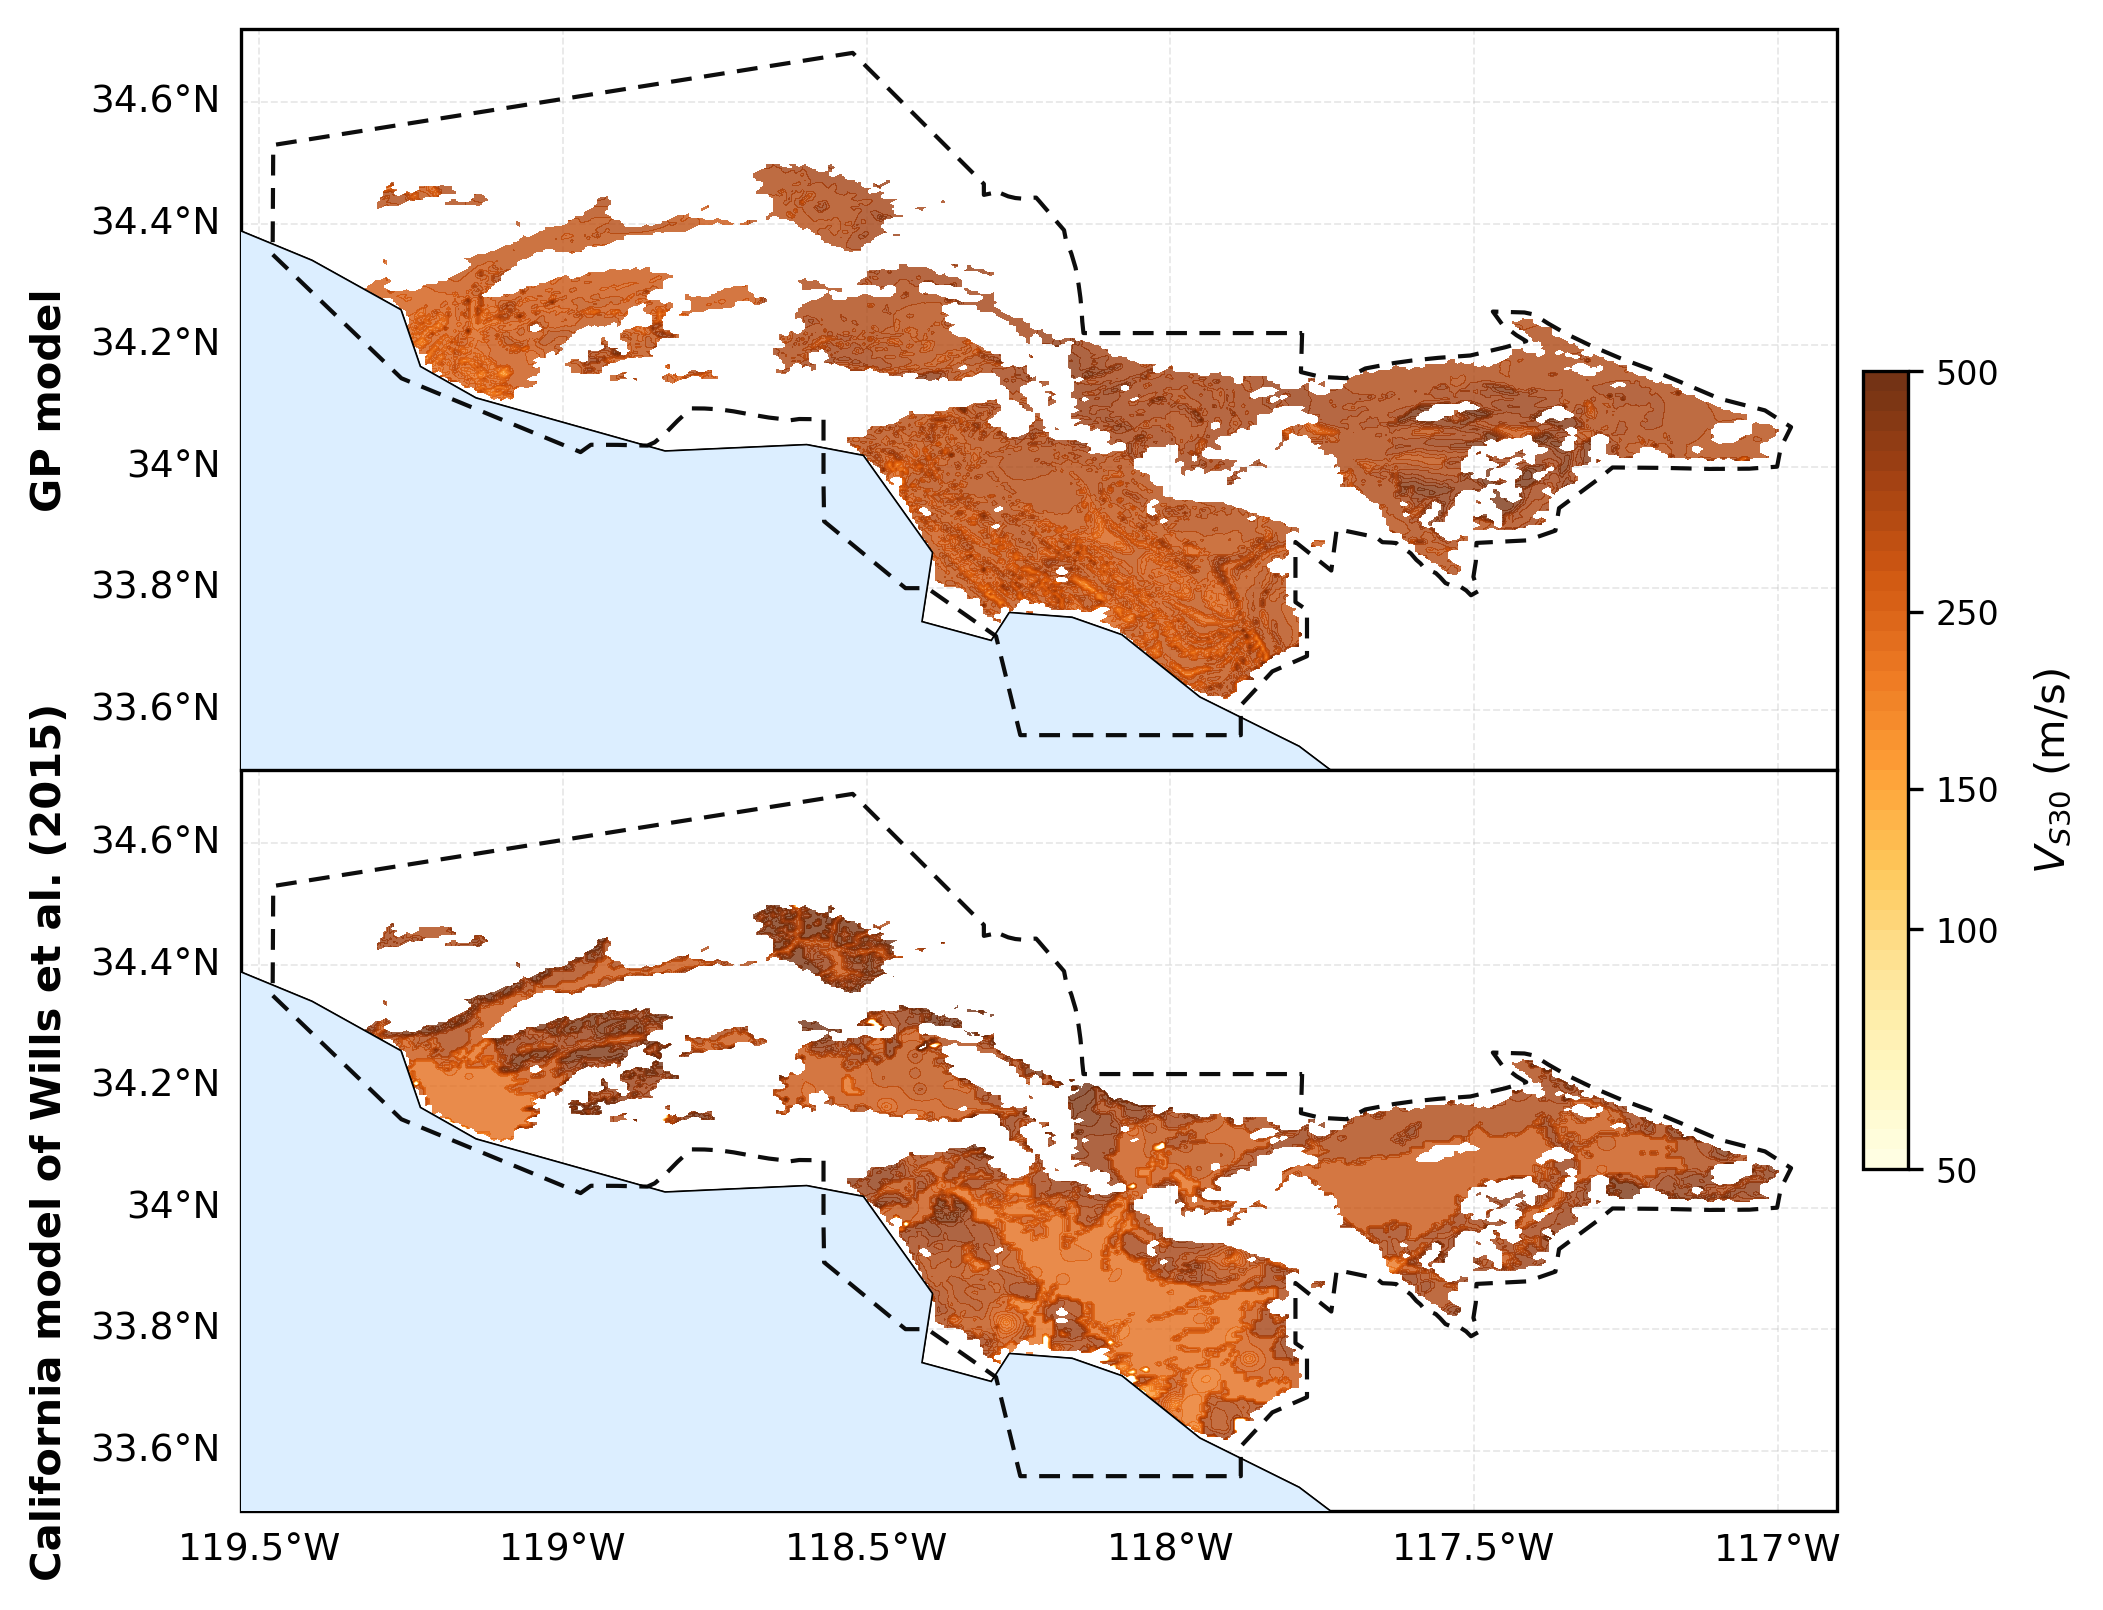

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import geopandas as gpd

from shapely.geometry import Polygon

plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.size"] = 12

# Read CVM-S4 basin boundary and mask points outside basin
gdf = gpd.read_file("CVM-S4_basins_boundary.gpkg")

# -------- boundary for masking: UTM coordinates --------
gdf_utm = gdf.to_crs("EPSG:32611")

line = gdf_utm.geometry.iloc[0]
coords = list(line.coords)
poly = Polygon(coords)

pts = gpd.GeoDataFrame(
    df_ucvm.copy(),
    geometry=gpd.points_from_xy(
        df_ucvm["easting"],
        df_ucvm["northing"]
    ),
    crs="EPSG:32611"
)

mask = pts.geometry.within(poly) | pts.geometry.touches(poly)

df_ucvm = pts.drop(columns="geometry").copy()

# Basin
df_ucvm.loc[~mask, "vs30_pred"] = np.nan
df_ucvm.loc[~mask, "wills"] = np.nan

# -------- boundary for plotting: longitude / latitude --------
gdf_boundary_ll = gdf.to_crs("EPSG:4326")


# Plot window
pl_win = [[33.5, 34.72], [-119.5293, -116.9023]]

latmin, latmax = pl_win[0]
lonmin, lonmax = pl_win[1]


# Prepare data
vs30_pred_data2plot = np.column_stack([
    df_ucvm["lat"].to_numpy().reshape(-1),
    df_ucvm["long"].to_numpy().reshape(-1),
    df_ucvm["vs30_pred"].to_numpy().reshape(-1)
])

wills_data2plot = np.column_stack([
    df_ucvm["lat"].to_numpy().reshape(-1),
    df_ucvm["long"].to_numpy().reshape(-1),
    df_ucvm["wills"].to_numpy().reshape(-1)
])


# Shared color scale
cmin = np.log(50)
cmax = np.log(500)

cmap = "YlOrBr"


# Create vertical figure
fig, axes = plt.subplots(
    2, 1,
    figsize=(8.5, 9.5),
    dpi=300,
    subplot_kw={"projection": ccrs.PlateCarree()}
)

ax1, ax2 = axes


# Top panel: GP model VS30
fig, ax1, cs1, _, data_crs, _ = PlotContourCAMap(
    vs30_pred_data2plot,
    cmin=cmin,
    cmax=cmax,
    log_cbar=True,
    frmt_clb="%.1f",
    cmap=cmap,
    ax=ax1,
    add_colorbar=False
)


# Bottom panel: Wills VS30
fig, ax2, cs2, _, data_crs, _ = PlotContourCAMap(
    wills_data2plot,
    cmin=cmin,
    cmax=cmax,
    log_cbar=True,
    frmt_clb="%.1f",
    cmap=cmap,
    ax=ax2,
    add_colorbar=False
)


# Common extent and dashed basin boundary
for ax in axes:
    ax.set_xlim(lonmin, lonmax)
    ax.set_ylim(latmin, latmax)

    # CVM-S4 basin boundary: dashed line
    ax.add_geometries(
        gdf_boundary_ll.geometry,
        crs=ccrs.PlateCarree(),
        facecolor="none",
        edgecolor="black",
        linewidth=1.0,
        linestyle=(0, (5, 3)),
        alpha=0.95,
        zorder=20
    )


# Put titles in a left column
ax1.text(
    -0.12, 0.5,
    r"GP model",
    transform=ax1.transAxes,
    rotation=90,
    va="center",
    ha="center",
    fontsize=10,
    fontweight="bold"
)

ax2.text(
    -0.12, 0.5,
    r"California model of Wills et al. (2015)",
    transform=ax2.transAxes,
    rotation=90,
    va="center",
    ha="center",
    fontsize=10,
    fontweight="bold"
)


# Gridlines and coordinate labels
# -------- top plot: keep left labels only --------
gl1 = ax1.gridlines(
    crs=data_crs,
    draw_labels=True,
    linewidth=0.45,
    color="0.65",
    alpha=0.25,
    linestyle="--"
)

gl1.top_labels = False
gl1.bottom_labels = False
gl1.right_labels = False
gl1.left_labels = True

gl1.xlabel_style = {"size": 9, "fontfamily": "Arial"}
gl1.ylabel_style = {"size": 9, "fontfamily": "Arial"}

try:
    gl1.xlabels_top = False
    gl1.xlabels_bottom = False
    gl1.ylabels_right = False
    gl1.ylabels_left = True
except AttributeError:
    pass


# -------- bottom plot: keep left and bottom labels --------
gl2 = ax2.gridlines(
    crs=data_crs,
    draw_labels=True,
    linewidth=0.45,
    color="0.65",
    alpha=0.25,
    linestyle="--"
)

gl2.top_labels = False
gl2.bottom_labels = True
gl2.right_labels = False
gl2.left_labels = True

gl2.xlabel_style = {"size": 9, "fontfamily": "Arial"}
gl2.ylabel_style = {"size": 9, "fontfamily": "Arial"}

try:
    gl2.xlabels_top = False
    gl2.xlabels_bottom = True
    gl2.ylabels_right = False
    gl2.ylabels_left = True
except AttributeError:
    pass

# Layout: leave space on the right for colorbar
fig.subplots_adjust(
    left=0.18,
    right=0.82,     
    bottom=0.08,
    top=0.60,
    hspace=0.00
)

# Vertical colorbar aligned with the lower panel
fig.canvas.draw()

pos1 = ax1.get_position()
pos2 = ax2.get_position()

cbar_x = pos2.x1 + 0.010
cbar_w = 0.018

gap_center = 0.5 * (pos1.y0 + pos2.y1)  
cbar_h = 0.28                           
cbar_y = gap_center - cbar_h / 2         

cax = fig.add_axes([
    cbar_x,
    cbar_y,
    cbar_w,
    cbar_h
])

cbar = fig.colorbar(
    cs1,
    cax=cax,
    orientation="vertical"
)

tick_vals = np.array([50, 100, 150, 250, 500])
cbar.set_ticks(np.log(tick_vals))
cbar.set_ticklabels([f"{v:.0f}" for v in tick_vals])

cbar.ax.tick_params(labelsize=8, pad=3)
cbar.set_label(r"$V_{S30}$ (m/s)", fontsize=10, labelpad=8)

cbar = fig.colorbar(
    cs1,
    cax=cax,
    orientation="vertical"
)

tick_vals = np.array([50, 100, 150, 250, 500])
cbar.set_ticks(np.log(tick_vals))
cbar.set_ticklabels([f"{v:.0f}" for v in tick_vals])

cbar.ax.tick_params(labelsize=8, pad=3)
cbar.set_label(r"$V_{S30}$ (m/s)", fontsize=10, labelpad=8)
plt.show()